In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from influxdb_client_3 import InfluxDBClient3

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
HOST = "http://127.0.0.1:8182"
DATABASE = "fan_monitor"
TOKEN = "apiv3_Ynk9eheNcAjK2R9iBR7cvoLFAlQgT2YMAap8L9_SflJ-KepGFg85yDsvO1yMq35NbhlaOzZGKFj6UMHOGNs6bQ"

client = InfluxDBClient3(
    host=HOST,
    database=DATABASE,
    token=TOKEN if TOKEN else None
)

print("Connected to InfluxDB!")

Connected to InfluxDB!


In [5]:
query = """
SELECT
    time,
    current,
    freq,
    amp,
    dev
FROM fan_telemetry
WHERE time >= (
    SELECT MIN(time) + INTERVAL '10' HOUR
    FROM fan_telemetry
)
ORDER BY time ASC
"""

table = client.query(
    query=query,
    language="sql"
)

df = table.to_pandas()
df_clean = df[df["amp"] > 0].copy()

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

Data loaded successfully!
Dataset shape: (81499, 5)


In [6]:
display(df.head(10))

,time,current,freq,amp,dev
0,2026-11-08 02:00:32.036961600,4.55,21.5,163257.9,fan1
1,2026-11-08 02:00:33.212157900,4.59,21.5,160520.9,fan1
2,2026-11-08 02:00:33.742187600,4.53,21.5,157925.0,fan1
3,2026-11-08 02:00:34.724160900,4.59,21.5,156801.3,fan1
4,2026-11-08 02:00:35.775256000,4.57,21.5,159797.1,fan1
5,2026-11-08 02:00:36.798305200,4.60,21.5,111952.5,fan1
6,2026-11-08 02:00:37.758780000,4.63,21.5,104046.3,fan1
7,2026-11-08 02:00:38.845619800,4.67,21.5,117821.8,fan1
8,2026-11-08 02:00:39.770262500,4.65,21.5,113942.5,fan1
9,2026-11-08 02:00:40.857155500,4.60,21.5,123391.5,fan1


In [7]:
df_clean = df[
    (df["amp"] > 0) &
    (df["freq"].notna()) &
    (df["amp"].notna())
].copy()

print("Raw shape:", df.shape)
print("Clean shape:", df_clean.shape)
print("Time range:", df_clean["time"].min(), "->", df_clean["time"].max())

Raw shape: (81499, 5)
Clean shape: (80998, 5)
Time range: 2026-11-08 02:00:32.036961600 -> 2026-11-09 02:27:51.692285600


In [8]:
# Select the two experimentally observed normal frequencies
NORMAL_FREQS = [19.5, 21.5]

df_normal = df_clean[
    df_clean["freq"].isin(NORMAL_FREQS)
].copy()

print("Normal dataset shape:", df_normal.shape)
print(df_normal["freq"].value_counts())

Normal dataset shape: (54312, 5)
freq
19.5    44793
21.5     9519
Name: count, dtype: int64


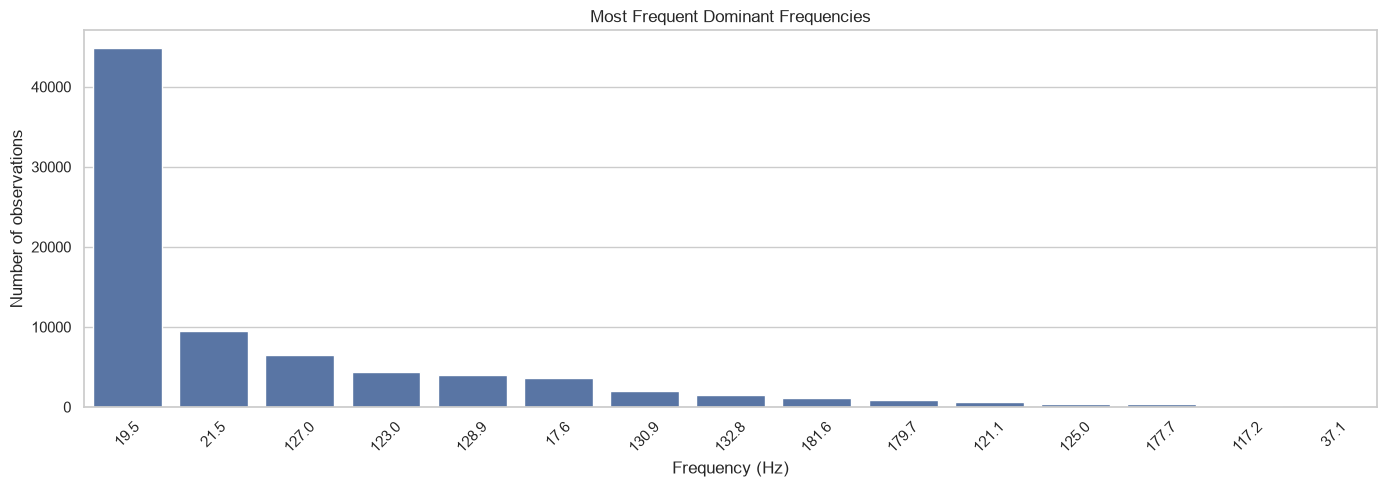

In [9]:
plt.figure(figsize=(14, 5))

sns.countplot(
    data=df_clean,
    x="freq",
    order=df_clean["freq"].value_counts().index[:15]
)

plt.title("Most Frequent Dominant Frequencies")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Number of observations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

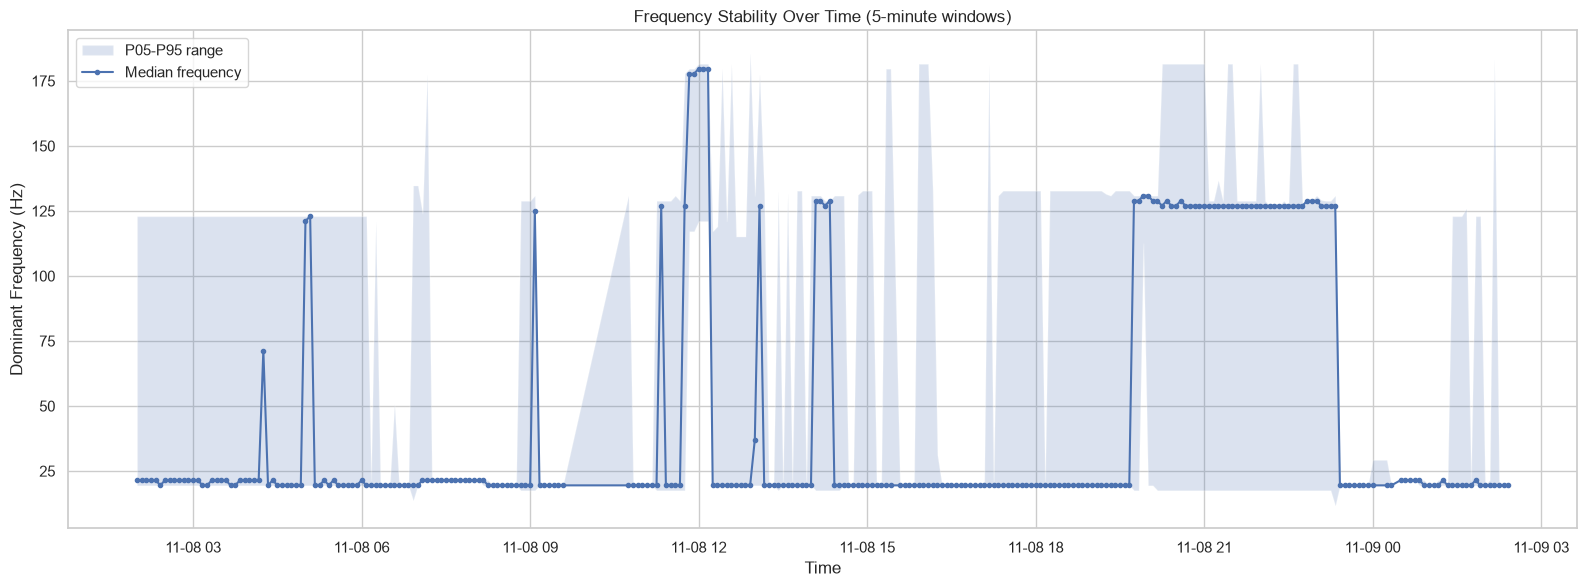

In [10]:
# ============================================================
# FREQUENCY STABILITY OVER TIME
# ============================================================

df_freq = df_clean.copy()
df_freq = df_freq.set_index("time").sort_index()

# Statistics per 5-minute window
freq_window = (
    df_freq["freq"]
    .resample("5min")
    .agg(
        count="count",
        median="median",
        mean="mean",
        std="std",
        p05=lambda x: x.quantile(0.05),
        p95=lambda x: x.quantile(0.95)
    )
)

# Exclude windows with insufficient observations
freq_window = freq_window[
    freq_window["count"] >= 100
]

# Plot
fig, ax = plt.subplots(figsize=(16, 6))

# P05-P95 range
ax.fill_between(
    freq_window.index,
    freq_window["p05"],
    freq_window["p95"],
    alpha=0.2,
    label="P05-P95 range"
)

# Median frequency
ax.plot(
    freq_window.index,
    freq_window["median"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Median frequency"
)

ax.set_xlabel("Time")
ax.set_ylabel("Dominant Frequency (Hz)")
ax.set_title("Frequency Stability Over Time (5-minute windows)")

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()